# Reweighing (Kamiran & Calders, 2012) on Adult, German and COMPAS

Pre-processing bias mitigation with AIF360's `Reweighing`. For each dataset:
1. fairness of the original labels (DP_Diff, DIR, consistency);
2. stratified train/test split, reweighing fitted on the training data only;
3. classifier trained with and without the weights; fairness and accuracy on the held-out test set.

Results are averaged over 10 random splits.

In [1]:
import os, urllib.request, warnings, logging
logging.disable(logging.WARNING)                 # hide AIF360 messages about optional dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import aif360
from aif360.datasets import AdultDataset, GermanDataset, CompasDataset
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.algorithms.preprocessing import Reweighing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, balanced_accuracy_score

warnings.filterwarnings("ignore")
pd.set_option("future.infer_string", False)   # AIF360 0.6 is not compatible with pandas 3 string dtype
pd.set_option("display.precision", 3)

SEEDS = range(10)       # number of random train/test splits
TEST_SIZE = 0.3
K_CONSISTENCY = 5       # neighbours used by the consistency measure

## 1. Data
AIF360 expects the raw files in its `data/raw` folder; they are downloaded from the original sources if missing.

In [2]:
RAW = os.path.join(os.path.dirname(aif360.__file__), "data", "raw")
SOURCES = {
    "adult": ["https://archive.ics.uci.edu/ml/machine-learning-databases/adult/" + f
              for f in ("adult.data", "adult.test", "adult.names")],
    "german": ["https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"],
    "compas": ["https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"],
}
for folder, urls in SOURCES.items():
    for url in urls:
        path = os.path.join(RAW, folder, url.split("/")[-1])
        if not os.path.exists(path):
            urllib.request.urlretrieve(url, path)

# name -> (AIF360 dataset, sensitive attribute, privileged value meaning)
DATASETS = {
    "Adult":  (AdultDataset(),  "sex",  "male"),          # favourable: income > 50K
    "German": (GermanDataset(), "age",  "age > 25"),      # favourable: good credit
    "COMPAS": (CompasDataset(), "race", "Caucasian"),     # favourable: no recidivism within 2 years
}
pd.DataFrame({name: {"rows": d.features.shape[0], "features": d.features.shape[1], "sensitive": s,
                     "privileged (=1)": p, "favourable rate": (d.labels.ravel() == d.favorable_label).mean()}
              for name, (d, s, p) in DATASETS.items()}).T

,rows,features,sensitive,privileged (=1),favourable rate
Adult,45222,98,sex,male,0.248
German,1000,58,age,age > 25,0.7
COMPAS,6167,401,race,Caucasian,0.545


## 2. Fairness measures
* **DP_Diff** = P(ŷ = fav | unprivileged) − P(ŷ = fav | privileged); 0 is fair, negative values disadvantage the unprivileged group.
* **DIR** = P(ŷ = fav | unprivileged) / P(ŷ = fav | privileged); 1 is fair (the "80 % rule" flags values below 0.8).
* **Consistency** = 1 − mean |ŷᵢ − mean of ŷ over the k nearest neighbours of i| (individual fairness; 1 is best). Neighbours are found on standardised features without the sensitive attribute.

In [3]:
def groups(sens):
    return [{sens: 0}], [{sens: 1}]   # unprivileged, privileged

def consistency(X, y, k=K_CONSISTENCY):
    X = StandardScaler().fit_transform(X)
    idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    return 1 - np.abs(y - y[idx].mean(axis=1)).mean()

def fairness(ds, sens, model_cols, y=None):
    """DP_Diff, DIR and consistency of the labels of `ds` (or of predictions `y`)."""
    ds = ds.copy()
    if y is not None:
        ds.labels = y.reshape(-1, 1)
    unpriv, priv = groups(sens)
    m = BinaryLabelDatasetMetric(ds, unprivileged_groups=unpriv, privileged_groups=priv)
    fav = (ds.labels.ravel() == ds.favorable_label).astype(float)
    return {"DP_Diff": m.statistical_parity_difference(), "DIR": m.disparate_impact(),
            "Consistency": consistency(ds.features[:, model_cols], fav)}

def model_columns(ds, sens, include_s=False):
    """Features given to the classifier: by default without the sensitive attribute (paper's assumption A2)."""
    return [i for i, f in enumerate(ds.feature_names) if include_s or f != sens]

## 3. Bias in the original labels (before mitigation and before any classifier)

In [4]:
before = pd.DataFrame({name: fairness(d, s, model_columns(d, s)) for name, (d, s, _) in DATASETS.items()}).T
before

,DP_Diff,DIR,Consistency
Adult,-0.199,0.363,0.793
German,-0.149,0.795,0.670
COMPAS,-0.097,0.840,0.601


## 4. Mitigation pipeline
For each split: stratified split on label × sensitive group → `Reweighing` fitted on the training set → classifier trained with the instance weights → predictions on the untouched test set. The baseline is the same classifier without weights.

In [6]:
CLASSIFIERS = {
    "LogReg": lambda seed: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "RandomForest": lambda seed: RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                        random_state=seed, n_jobs=-1),
}

def run(name, ds, sens, seed, include_s=False, classifiers=CLASSIFIERS):
    cols = model_columns(ds, sens, include_s)
    strata = ds.labels.ravel().astype(int) * 2 + ds.protected_attributes[:, ds.protected_attribute_names.index(sens)].astype(int)
    tr_idx, te_idx = train_test_split(np.arange(len(strata)), test_size=TEST_SIZE, stratify=strata, random_state=seed)
    train, test = ds.subset(tr_idx), ds.subset(te_idx)

    unpriv, priv = groups(sens)
    train_rw = Reweighing(unprivileged_groups=unpriv, privileged_groups=priv).fit_transform(train)
    w_train = BinaryLabelDatasetMetric(train_rw, unprivileged_groups=unpriv, privileged_groups=priv)

    rows = []
    for clf_name, make in classifiers.items():
        for method, weights in [("Baseline", None), ("Reweighing", train_rw.instance_weights)]:
            clf = make(seed)
            fit_kw = {} if weights is None else ({"logisticregression__sample_weight": weights}
                                                 if clf_name == "LogReg" else {"sample_weight": weights})
            clf.fit(train.features[:, cols], train.labels.ravel(), **fit_kw)
            y_pred = clf.predict(test.features[:, cols])
            rows.append({"dataset": name, "classifier": clf_name, "method": method, "seed": seed,
                         "Accuracy": accuracy_score(test.labels.ravel(), y_pred),
                         "BalAcc": balanced_accuracy_score(test.labels.ravel(), y_pred),
                         **fairness(test, sens, cols, y_pred)})
    check = {"dataset": name, "seed": seed, "DP_Diff train (original)":
             BinaryLabelDatasetMetric(train, unprivileged_groups=unpriv, privileged_groups=priv).statistical_parity_difference(),
             "DP_Diff train (reweighed)": w_train.statistical_parity_difference(),
             "DP_Diff test labels": fairness(test, sens, cols)["DP_Diff"]}
    return rows, check

results, checks = [], []
for name, (ds, sens, _) in DATASETS.items():
    for seed in SEEDS:
        r, c = run(name, ds, sens, seed)
        results += r; checks.append(c)
results = pd.DataFrame(results)
results.to_csv("results_per_split.csv", index=False)

Sanity check: after reweighing, the weighted training data have a DP_Diff of 0.

In [7]:
pd.DataFrame(checks).groupby("dataset").mean().drop(columns="seed")

,DP_Diff train (original),DP_Diff train (reweighed),DP_Diff test labels
dataset,,,
Adult,-0.199,-6.661e-17,-0.199
COMPAS,-0.097,1.221e-16,-0.097
German,-0.149,-2.331e-16,-0.149


## 5. Results on the held-out test data (mean ± sd over 10 splits)

In [8]:
metrics = ["Accuracy", "BalAcc", "DP_Diff", "DIR", "Consistency"]
agg = results.groupby(["dataset", "classifier", "method"], sort=False)[metrics].agg(["mean", "std"])
table = pd.DataFrame({m: agg[(m, "mean")].map("{:.3f}".format) + " ± " + agg[(m, "std")].map("{:.3f}".format)
                      for m in metrics})
table.to_csv("results_summary.csv")
table

Accuracy         BalAcc         DP_Diff  \
dataset classifier   method                                                     
Adult   LogReg       Baseline    0.849 ± 0.003  0.766 ± 0.005  -0.179 ± 0.006   
                     Reweighing  0.843 ± 0.003  0.749 ± 0.004  -0.093 ± 0.005   
        RandomForest Baseline    0.860 ± 0.003  0.773 ± 0.004  -0.176 ± 0.005   
                     Reweighing  0.855 ± 0.002  0.759 ± 0.003  -0.092 ± 0.004   
German  LogReg       Baseline    0.748 ± 0.023  0.678 ± 0.020  -0.137 ± 0.047   
                     Reweighing  0.743 ± 0.029  0.668 ± 0.027  -0.094 ± 0.036   
        RandomForest Baseline    0.758 ± 0.017  0.631 ± 0.021  -0.059 ± 0.046   
                     Reweighing  0.754 ± 0.010  0.626 ± 0.014  -0.024 ± 0.043   
COMPAS  LogReg       Baseline    0.669 ± 0.007  0.661 ± 0.006  -0.153 ± 0.024   
                     Reweighing  0.669 ± 0.009  0.660 ± 0.008  -0.144 ± 0.024   
        RandomForest Baseline    0.676 ± 0.012  0.663 ± 0.011  -0.150 ± 0.013   
                     Reweighing  0.674 ± 0.015  0.660 ± 0.015  -0.140 ± 0.017   

                                           DIR    Consistency  
dataset classifier   method                                    
Adult   LogReg       Baseline    0.311 ± 0.014  0.927 ± 0.002  
                     Reweighing  0.573 ± 0.017  0.930 ± 0.002  
        RandomForest Baseline    0.287 ± 0.011  0.933 ± 0.002  
                     Reweighing  0.555 ± 0.012  0.936 ± 0.003  
German  LogReg       Baseline    0.824 ± 0.057  0.760 ± 0.010  
                     Reweighing  0.878 ± 0.045  0.763 ± 0.015  
        RandomForest Baseline    0.934 ± 0.052  0.845 ± 0.015  
                     Reweighing  0.972 ± 0.051  0.843 ± 0.023  
COMPAS  LogReg       Baseline    0.784 ± 0.030  0.826 ± 0.006  
                     Reweighing  0.797 ± 0.030  0.828 ± 0.005  
        RandomForest Baseline    0.804 ± 0.016  0.827 ± 0.010  
                     Reweighing  0.816 ± 0.021  0.827 ± 0.008

## 6. Fairness before vs. after mitigation

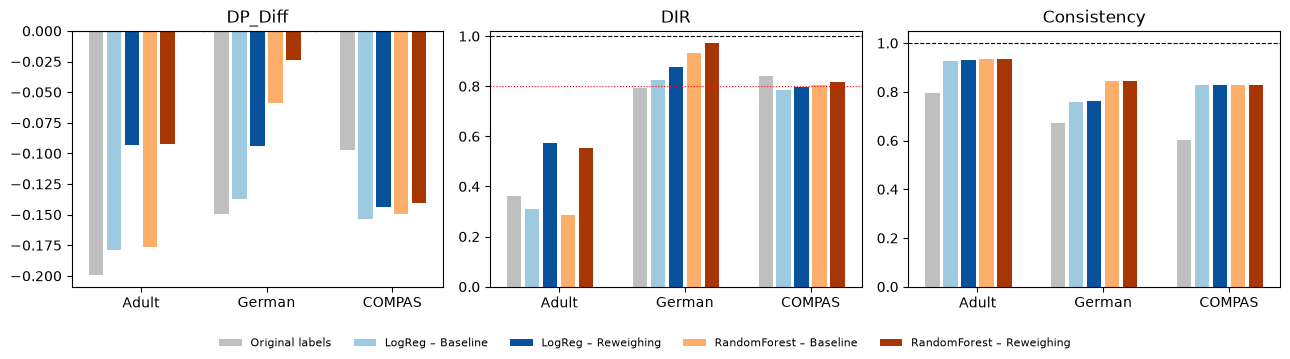

In [9]:
summary = results.groupby(["dataset", "classifier", "method"], sort=False)[metrics].mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, m in zip(axes, ["DP_Diff", "DIR", "Consistency"]):
    labels, x = [], 0
    for name in DATASETS:
        ax.bar(x, before.loc[name, m], color="0.75", label="Original labels" if x == 0 else None)
        for j, (clf, method, c) in enumerate([("LogReg", "Baseline", "#9ecae1"), ("LogReg", "Reweighing", "#08519c"),
                                               ("RandomForest", "Baseline", "#fdae6b"), ("RandomForest", "Reweighing", "#a63603")]):
            v = summary.query("dataset == @name and classifier == @clf and method == @method")[m].item()
            ax.bar(x + 1 + j, v, color=c, label=f"{clf} – {method}" if x == 0 else None)
        labels.append((x + 2.5, name)); x += 7
    ax.axhline({"DP_Diff": 0, "DIR": 1, "Consistency": 1}[m], color="k", lw=0.8, ls="--")
    if m == "DIR":
        ax.axhline(0.8, color="red", lw=0.8, ls=":")
    ax.set_xticks([p for p, _ in labels], [n for _, n in labels]); ax.set_title(m)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.savefig("fairness_before_after.png", dpi=200); plt.show()

## 7. Extra: sensitive attribute available to the classifier
The paper's second scenario: the same pipeline (logistic regression) when the sensitive attribute is also a model feature.

In [10]:
with_s = []
for name, (ds, sens, _) in DATASETS.items():
    for seed in SEEDS:
        with_s += run(name, ds, sens, seed, include_s=True, classifiers={"LogReg": CLASSIFIERS["LogReg"]})[0]
with_s = pd.DataFrame(with_s)
with_s.groupby(["dataset", "method"], sort=False)[metrics].mean()

Accuracy  BalAcc  DP_Diff    DIR  Consistency
dataset method                                                   
Adult   Baseline       0.848   0.766   -0.186  0.292        0.927
        Reweighing     0.842   0.748   -0.087  0.599        0.928
German  Baseline       0.750   0.676   -0.221  0.724        0.762
        Reweighing     0.742   0.668   -0.060  0.923        0.763
COMPAS  Baseline       0.668   0.660   -0.165  0.770        0.809
        Reweighing     0.666   0.657   -0.006  0.990        0.803